### Reference:
- https://learn.deeplearning.ai/courses/diffusion-models/

# Overview: Sampling
- This notebook shows how to perform sampling using DDPM on a trained diffusion model
- The model architecture used is U-Net.

In [1]:
from typing import Dict, Tuple
from tqdm import tqdm
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import models, transforms
from torchvision.utils import save_image, make_grid
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
import numpy as np
from IPython.display import HTML
from diffusion_utilities import *

# Model - UNet

In [2]:
class ContextUnet(nn.Module):
    def __init__(self, in_channels, n_feat=256, n_cfeat=10, height=28):  # cfeat - context features
        super(ContextUnet, self).__init__()

        # number of input channels, number of intermediate feature maps and number of classes
        self.in_channels = in_channels
        self.n_feat = n_feat
        self.n_cfeat = n_cfeat
        self.h = height  #assume h == w. must be divisible by 4, so 28,24,20,16...

        # Initialize the initial convolutional layer
        self.init_conv = ResidualConvBlock(in_channels, n_feat, is_res=True)

        # Initialize the down-sampling path of the U-Net with two levels
        self.down1 = UnetDown(n_feat, n_feat)        # down1 #[10, 256, 8, 8]
        self.down2 = UnetDown(n_feat, 2 * n_feat)    # down2 #[10, 256, 4,  4]
        
         # original: self.to_vec = nn.Sequential(nn.AvgPool2d(7), nn.GELU())
        self.to_vec = nn.Sequential(nn.AvgPool2d((4)), nn.GELU())

        # Embed the timestep and context labels with a one-layer fully connected neural network
        self.timeembed1 = EmbedFC(1, 2*n_feat)
        self.timeembed2 = EmbedFC(1, 1*n_feat)
        self.contextembed1 = EmbedFC(n_cfeat, 2*n_feat)
        self.contextembed2 = EmbedFC(n_cfeat, 1*n_feat)

        # Initialize the up-sampling path of the U-Net with three levels
        self.up0 = nn.Sequential(
            nn.ConvTranspose2d(2 * n_feat, 2 * n_feat, self.h//4, self.h//4), # up-sample  
            nn.GroupNorm(8, 2 * n_feat), # normalize                       
            nn.ReLU(),
        )
        self.up1 = UnetUp(4 * n_feat, n_feat)
        self.up2 = UnetUp(2 * n_feat, n_feat)

        # Initialize the final convolutional layers to map to the same number of channels as the input image
        self.out = nn.Sequential(
            nn.Conv2d(2 * n_feat, n_feat, 3, 1, 1), # reduce number of feature maps   #in_channels, out_channels, kernel_size, stride=1, padding=0
            nn.GroupNorm(8, n_feat), # normalize
            nn.ReLU(),
            nn.Conv2d(n_feat, self.in_channels, 3, 1, 1), # map to same number of channels as input
        )

    def forward(self, x, t, c=None):
        """
        x : (batch, n_feat, h, w) : input image
        t : (batch, n_cfeat)      : time step
        c : (batch, n_classes)    : context label
        """
        # x is the input image, c is the context label, t is the timestep, context_mask says which samples to block the context on
        if VERBOSE: print(f"Input x.shape: {x.shape}, t.shape: {t.shape}")

        # pass the input image through the initial convolutional layer
        x = self.init_conv(x)
        if VERBOSE: print(f"After init_conv x.shape: {x.shape}")
        # pass the result through the down-sampling path
        down1 = self.down1(x)       #[10, 256, 8, 8]
        down2 = self.down2(down1)   #[10, 256, 4, 4]
        if VERBOSE: print(f"down1.shape: {down1.shape}")
        if VERBOSE: print(f"down2.shape: {down2.shape}")

        # convert the feature maps to a vector and apply an activation
        hiddenvec = self.to_vec(down2)
        if VERBOSE: print(f"hiddenvec.shape: {hiddenvec.shape}\n")
        
        # mask out context if context_mask == 1
        if c is None:
            c = torch.zeros(x.shape[0], self.n_cfeat).to(x)
            if VERBOSE: print(f"No context given. c.shape: {c.shape}")
            
        # embed context and timestep
        cemb1 = self.contextembed1(c).view(-1, self.n_feat * 2, 1, 1)     # (batch, 2*n_feat, 1,1)
        temb1 = self.timeembed1(t).view(-1, self.n_feat * 2, 1, 1)
        cemb2 = self.contextembed2(c).view(-1, self.n_feat, 1, 1)
        temb2 = self.timeembed2(t).view(-1, self.n_feat, 1, 1)
        if VERBOSE: print(f"cemb1 {cemb1.shape}, temb1 {temb1.shape}, cemb2 {cemb2.shape}, temb2 {temb2.shape}")

        up1 = self.up0(hiddenvec)
        up2 = self.up1(cemb1*up1 + temb1, down2)  # add and multiply embeddings
        up3 = self.up2(cemb2*up2 + temb2, down1)
        out = self.out(torch.cat((up3, x), 1))
        if VERBOSE: print(f"up1.shape: {up1.shape}")
        if VERBOSE: print(f"up2.shape: {up2.shape}")
        if VERBOSE: print(f"up3.shape: {up3.shape}")
        if VERBOSE: print(f"out.shape: {out.shape}")
        return out


In [3]:
# network hyperparameters
device = torch.device("cuda:0" if torch.cuda.is_available() else torch.device('cpu'))
n_feat = 64 # 64 hidden dimension feature
n_cfeat = 5 # context vector is of size 5
height = 16 # 16x16 image
save_dir = './weights/'

In [4]:
# construct model
nn_model = ContextUnet(in_channels=3, n_feat=n_feat, n_cfeat=n_cfeat, height=height).to(device)

In [5]:
# Just for debug
VERBOSE=True
timesteps = 500
with torch.no_grad():
    samples = torch.randn(1, 3, height, height).to(device)  
    i = timesteps
    t = torch.tensor([i / timesteps])[:, None, None, None].to(device)
    print(f"n_feat:{n_feat}, n_cfeat: {n_cfeat}, height: {height}\n")
    nn_model(samples, t)
VERBOSE=False

n_feat:64, n_cfeat: 5, height: 16

Input x.shape: torch.Size([1, 3, 16, 16]), t.shape: torch.Size([1, 1, 1, 1])
After init_conv x.shape: torch.Size([1, 64, 16, 16])
down1.shape: torch.Size([1, 64, 8, 8])
down2.shape: torch.Size([1, 128, 4, 4])
hiddenvec.shape: torch.Size([1, 128, 1, 1])

No context given. c.shape: torch.Size([1, 5])
cemb1 torch.Size([1, 128, 1, 1]), temb1 torch.Size([1, 128, 1, 1]), cemb2 torch.Size([1, 64, 1, 1]), temb2 torch.Size([1, 64, 1, 1])
up1.shape: torch.Size([1, 128, 4, 4])
up2.shape: torch.Size([1, 64, 8, 8])
up3.shape: torch.Size([1, 64, 16, 16])
out.shape: torch.Size([1, 3, 16, 16])


## DDPM Noise Schedule

In [6]:
# diffusion hyperparameters
timesteps = 500
beta1 = 1e-4
beta2 = 0.02

In [7]:
# construct DDPM noise schedule
b_t = (beta2 - beta1) * torch.linspace(0, 1, timesteps + 1, device=device) + beta1
a_t = 1 - b_t
ab_t = torch.cumsum(a_t.log(), dim=0).exp()    
ab_t[0] = 1

print(a_t.shape, b_t.shape, ab_t.shape)

torch.Size([501]) torch.Size([501]) torch.Size([501])


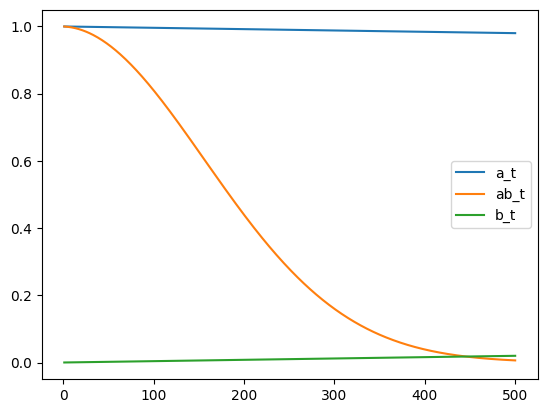

In [8]:
t = list(range(1, timesteps+1))
plt.plot(t, a_t[1:], label='a_t')
plt.plot(t, ab_t[1:], label='ab_t')
plt.plot(t, b_t[1:], label='b_t')
plt.legend()
plt.show()

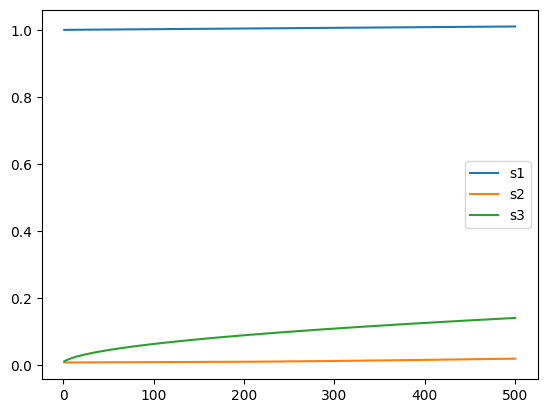

In [9]:
t = list(range(1, timesteps+1))
plt.plot(t, (1/a_t.sqrt())[1:], label='s1')
plt.plot(t, ((1 - a_t) / (1 - ab_t).sqrt())[1:], label='s2')
plt.plot(t, b_t.sqrt()[1:], label='s3')
plt.legend()
plt.show()

In [10]:
# helper function; removes the predicted noise (but adds some noise back in to avoid collapse)
def denoise_add_noise(x, t, pred_noise, z=None):
    if z is None:
        z = torch.randn_like(x)
    # s3*z
    noise = b_t.sqrt()[t] * z  
    # (x - pred_noise*s2) * s1
    mean = (x - pred_noise * ((1 - a_t[t]) / (1 - ab_t[t]).sqrt())) / a_t[t].sqrt()
    return mean + noise

# Sampling

In [11]:
# load in model weights and set to eval mode
nn_model.load_state_dict(torch.load(f"{save_dir}/model_trained.pth", map_location=device))
nn_model.eval()
print("Loaded in Model")

Loaded in Model


In [12]:
# sample using standard algorithm
@torch.no_grad()
def sample_ddpm(n_sample, save_rate=20):
    # x_T ~ N(0, 1), sample initial noise
    samples = torch.randn(n_sample, 3, height, height).to(device)  

    # array to keep track of generated steps for plotting
    intermediate = [] 
    for i in range(timesteps, 0, -1):
        print(f'sampling timestep {i:3d}', end='\r')

        # reshape time tensor
        t = torch.tensor([i / timesteps])[:, None, None, None].to(device)

        # sample some random noise to inject back in. 
        # For i = 1, don't add back in noise
        z = torch.randn_like(samples) if i > 1 else 0

        eps = nn_model(samples, t)    # predict noise e_(x_t,t)
        samples = denoise_add_noise(samples, i, eps, z)
        if i % save_rate ==0 or i==timesteps or i<8:
            intermediate.append(samples.detach().cpu().numpy())

    intermediate = np.stack(intermediate)
    return samples, intermediate

In [13]:
# visualize samples
plt.clf()
samples, intermediate_ddpm = sample_ddpm(32)
animation_ddpm = plot_sample(intermediate_ddpm,32,4,save_dir, "ani_run", None, save=True)
HTML(animation_ddpm.to_jshtml())

saved gif at ./weights/ani_run_wNone.gif


<Figure size 640x480 with 0 Axes>

#### Demonstrate incorrectly sample without adding the 'extra noise'

In [14]:
# incorrectly sample without adding in noise
@torch.no_grad()
def sample_ddpm_incorrect(n_sample):
    # x_T ~ N(0, 1), sample initial noise
    samples = torch.randn(n_sample, 3, height, height).to(device)  

    # array to keep track of generated steps for plotting
    intermediate = [] 
    for i in range(timesteps, 0, -1):
        print(f'sampling timestep {i:3d}', end='\r')

        # reshape time tensor
        t = torch.tensor([i / timesteps])[:, None, None, None].to(device)

        # don't add back in noise
        z = 0

        eps = nn_model(samples, t)    # predict noise e_(x_t,t)
        samples = denoise_add_noise(samples, i, eps, z)
        if i%20==0 or i==timesteps or i<8:
            intermediate.append(samples.detach().cpu().numpy())

    intermediate = np.stack(intermediate)
    return samples, intermediate

In [15]:
# visualize samples
plt.clf()
samples, intermediate = sample_ddpm_incorrect(32)
animation = plot_sample(intermediate,32,4,save_dir, "ani_run", None, save=False)
HTML(animation.to_jshtml())

<Figure size 640x480 with 0 Axes>

# Acknowledgments
Sprites by ElvGames, [FrootsnVeggies](https://zrghr.itch.io/froots-and-veggies-culinary-pixels) and  [kyrise](https://kyrise.itch.io/)   
This code is modified from, https://github.com/cloneofsimo/minDiffusion   
Diffusion model is based on [Denoising Diffusion Probabilistic Models](https://arxiv.org/abs/2006.11239) and [Denoising Diffusion Implicit Models](https://arxiv.org/abs/2010.02502)
